# ASL Alphabet Classifier (Google Colab)
**Dataset:** Kaggle `grassknoted/asl-alphabet` | **Model:** MobileNetV2 transfer learning

**Pehle ye karo:** `Runtime > Change runtime type > T4 GPU` select karo, phir cells ko upar se neeche ek ek karke run karo (ya `Runtime > Run all`).

Training 2 phases mein hogi: Phase 1 = 8 epochs (head), Phase 2 = 12 epochs (fine-tuning). EarlyStopping ki wajah se pehle bhi ruk sakti hai.

## 1. GPU check aur installs

In [1]:
!pip install -q kagglehub

import tensorflow as tf
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
assert gpus, "GPU nahi mila! Runtime > Change runtime type > T4 GPU select karo, phir dobara run karo."

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Imports aur settings

In [2]:
import os, json, shutil, subprocess
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
IMG_SIZE = (160, 160)
BATCH_SIZE = 64
VAL_TEST_SPLIT = 0.15
EPOCHS_PHASE1 = 8
EPOCHS_PHASE2 = 12
LR_PHASE1 = 1e-3
LR_PHASE2 = 3e-5
FINE_TUNE_LAST_N_LAYERS = 40
LABEL_SMOOTHING = 0.1
DROPOUT = 0.3
OUT_DIR = "/content/asl_output"
AUTOTUNE = tf.data.AUTOTUNE

os.makedirs(OUT_DIR, exist_ok=True)
keras.utils.set_random_seed(SEED)
print("Settings ready")

Settings ready


## 3. Dataset download (Kaggle)
Pehle `kagglehub` try hota hai. Agar wo fail ho to `kaggle.json` upload karne ko kahega (Kaggle > Settings > Create New Token).

In [3]:
def search_train_dir(root):
    for dirpath, dirnames, _ in os.walk(root):
        if {"A", "B", "space"}.issubset(set(dirnames)):
            return dirpath
    return None

try:
    import kagglehub
    root = kagglehub.dataset_download("grassknoted/asl-alphabet")
except Exception as e:
    print("kagglehub fail hua:", e)
    from google.colab import files
    print("Apni kaggle.json file upload karo:")
    up = files.upload()
    os.makedirs("/root/.kaggle", exist_ok=True)
    with open("/root/.kaggle/kaggle.json", "wb") as f:
        f.write(up["kaggle.json"])
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    subprocess.run(["kaggle", "datasets", "download", "-d", "grassknoted/asl-alphabet",
                    "--unzip", "-p", "/content/asl_data"], check=True)
    root = "/content/asl_data"

DATA_DIR = search_train_dir(root)
assert DATA_DIR is not None, "Train folder nahi mila"
print("Train dir:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Train dir: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## 4. Data pipeline (train / validation / test)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
train_raw, val_test_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
    validation_split=VAL_TEST_SPLIT,
    subset="both",
)
class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
print("Classes (%d): %s" % (NUM_CLASSES, class_names))

n_batches = int(val_test_raw.cardinality().numpy())
half = n_batches // 2
test_ds = val_test_raw.take(half).prefetch(AUTOTUNE)
val_ds = val_test_raw.skip(half).prefetch(AUTOTUNE)

augment = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augmentation")

train_ds = train_raw.map(lambda x, y: (augment(x, training=True), y),
                         num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("Train batches:", int(train_raw.cardinality().numpy()),
      "| Val batches:", int(val_ds.cardinality().numpy()),
      "| Test batches:", int(test_ds.cardinality().numpy()))

Found 87000 files belonging to 29 classes.
Using 73950 files for training.
Using 13050 files for validation.
Classes (29): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Train batches: 1156 | Val batches: 102 | Test batches: 102


## 5. Kuch sample images dekho (augmented)

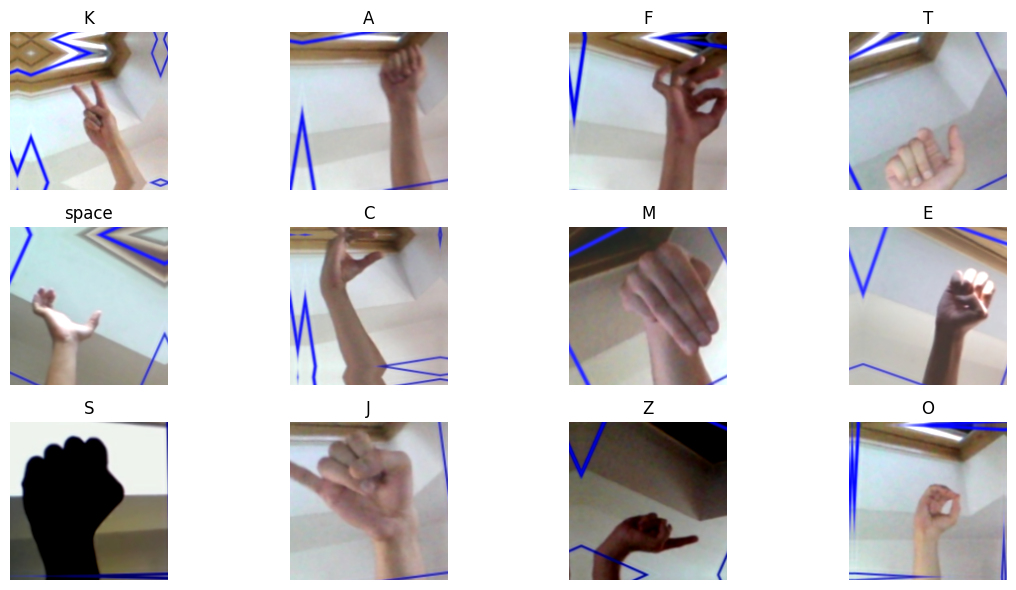

In [6]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(np.argmax(labels[i].numpy()))])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Model banao

In [7]:
def build_model(num_classes):
    inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="rescale")(inputs)
    base = keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(DROPOUT, name="drop1")(x)
    x = layers.Dense(256, activation="relu", name="fc")(x)
    x = layers.Dropout(DROPOUT, name="drop2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32", name="probs")(x)
    return keras.Model(inputs, outputs, name="asl_mobilenetv2"), base

def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=["accuracy"],
    )

def make_callbacks(ckpt_name):
    return [
        keras.callbacks.ModelCheckpoint(os.path.join(OUT_DIR, ckpt_name),
                                        monitor="val_accuracy", save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=2, min_lr=1e-7, verbose=1),
    ]

model, base = build_model(NUM_CLASSES)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "asl_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Dense)                      │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,373 (9.89 MB)

 Trainable params: 335,389 (1.28 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Phase 1: sirf head train (base frozen)

In [8]:
compile_model(model, LR_PHASE1)
h1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=make_callbacks("best_phase1.keras"),
)

Epoch 1/8
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.4715 - loss: 2.1861
Epoch 1: val_accuracy improved from None to 0.88914, saving model to /content/asl_output/best_phase1.keras

Epoch 1: finished saving model to /content/asl_output/best_phase1.keras
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 605s 511ms/step - accuracy: 0.6096 - loss: 1.7867 - val_accuracy: 0.8891 - val_loss: 1.1079 - learning_rate: 0.0010
Epoch 2/8
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.7311 - loss: 1.4755
Epoch 2: val_accuracy improved from 0.88914 to 0.91214, saving model to /content/asl_output/best_phase1.keras

Epoch 2: finished saving model to /content/asl_output/best_phase1.keras
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 483s 417ms/step - accuracy: 0.7425 - loss: 1.4467 - val_accuracy: 0.9121 - val_loss: 1.0357 - learning_rate: 0.0010
Epoch 3/8
1155/1156 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.7594 - loss: 1.3977
Epoch 3: val_accuracy improved from 0.91214 to 0.92395, saving model to /con

## 8. Phase 2: fine-tuning (top layers unfreeze)

In [9]:
base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAST_N_LAYERS]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_PHASE2)
h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    callbacks=make_callbacks("best_phase2.keras"),
)

Epoch 1/12
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.8796 - loss: 1.1109
Epoch 1: val_accuracy improved from None to 0.98773, saving model to /content/asl_output/best_phase2.keras

Epoch 1: finished saving model to /content/asl_output/best_phase2.keras
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 529s 444ms/step - accuracy: 0.9110 - loss: 1.0285 - val_accuracy: 0.9877 - val_loss: 0.7744 - learning_rate: 3.0000e-05
Epoch 2/12
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.9558 - loss: 0.9060
Epoch 2: val_accuracy improved from 0.98773 to 0.98865, saving model to /content/asl_output/best_phase2.keras

Epoch 2: finished saving model to /content/asl_output/best_phase2.keras
1156/1156 ━━━━━━━━━━━━━━━━━━━━ 491s 425ms/step - accuracy: 0.9617 - loss: 0.8875 - val_accuracy: 0.9887 - val_loss: 0.7578 - learning_rate: 3.0000e-05
Epoch 3/12
1155/1156 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.9728 - loss: 0.8418
Epoch 3: val_accuracy improved from 0.98865 to 0.99555, saving mo

## 9. Training curves

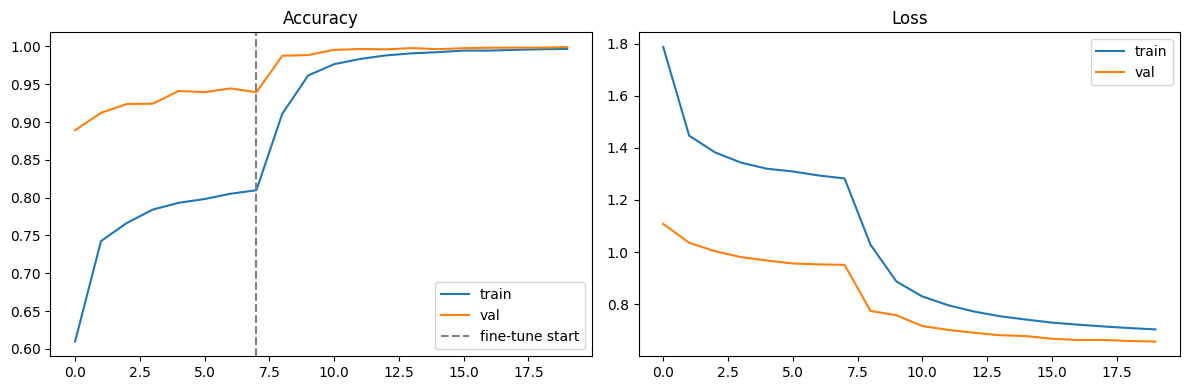

In [10]:
acc = h1.history["accuracy"] + h2.history["accuracy"]
val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss = h1.history["loss"] + h2.history["loss"]
val_loss = h1.history["val_loss"] + h2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val")
ax[0].axvline(len(h1.history["accuracy"]) - 1, color="gray", linestyle="--", label="fine-tune start")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=120)
plt.show()

## 10. Test set par evaluation

TEST ACCURACY: 0.9989

              precision    recall  f1-score   support

           A     0.9958    0.9958    0.9958       237
           B     1.0000    1.0000    1.0000       234
           C     1.0000    1.0000    1.0000       212
           D     1.0000    0.9961    0.9980       255
           E     1.0000    1.0000    1.0000       215
           F     1.0000    0.9962    0.9981       260
           G     1.0000    1.0000    1.0000       231
           H     1.0000    1.0000    1.0000       205
           I     1.0000    1.0000    1.0000       207
           J     0.9959    1.0000    0.9979       240
           K     1.0000    1.0000    1.0000       202
           L     1.0000    1.0000    1.0000       215
           M     0.9916    1.0000    0.9958       237
           N     1.0000    0.9947    0.9973       187
           O     0.9956    1.0000    0.9978       224
           P     0.9958    1.0000    0.9979       238
           Q     1.0000    0.9960    0.9980       248
    

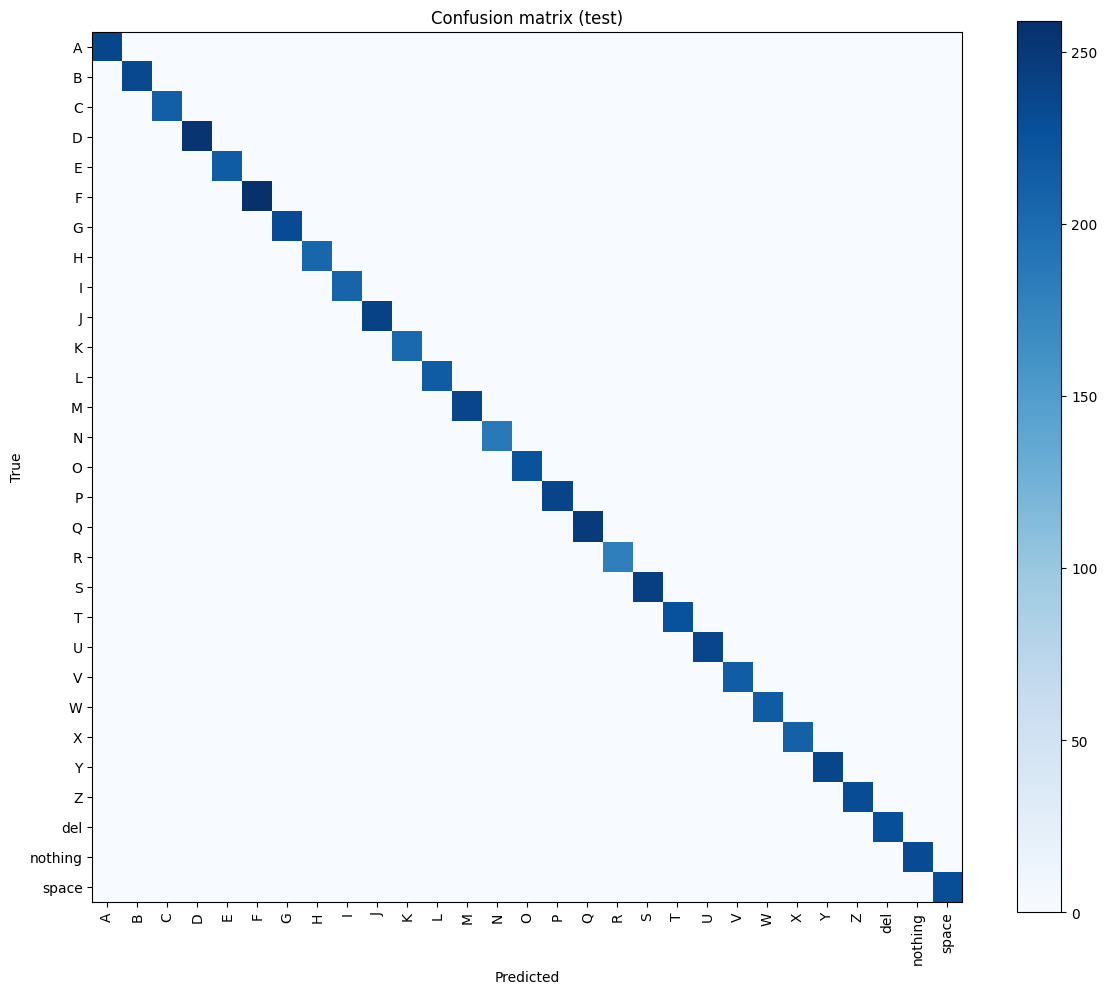

In [11]:
y_true, y_pred = [], []
for imgs, lbls in test_ds:
    probs = model.predict(imgs, verbose=0)
    y_pred.extend(np.argmax(probs, axis=1))
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
y_true, y_pred = np.array(y_true), np.array(y_pred)

test_acc = float((y_true == y_pred).mean())
print(f"TEST ACCURACY: {test_acc:.4f}\n")
report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
print(report)
with open(os.path.join(OUT_DIR, "classification_report.txt"), "w") as f:
    f.write(f"Test accuracy: {test_acc:.4f}\n\n{report}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test)")
plt.colorbar(); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=120)
plt.show()

## 10b. Dataset ka official test set (sirf 29 images)
Dataset ke `asl_alphabet_test` folder mein har class ki 1 image hoti hai. Ye real-world jaisi images hain, isliye ye asli check hai ke model sirf train data yaad to nahi kar gaya.

In [12]:
import glob
test_files = sorted(p for p in glob.glob(os.path.join(root, "**", "*.jpg"), recursive=True)
                   if "asl_alphabet_test" in p)
print("Official test images mili:", len(test_files))

correct, total, wrong = 0, 0, []
for p in test_files:
    true_name = os.path.basename(p).split("_")[0]
    if true_name not in class_names:
        continue
    arr = keras.utils.img_to_array(keras.utils.load_img(p, target_size=IMG_SIZE))[None]
    probs = model.predict(arr, verbose=0)[0]
    pred_name = class_names[int(np.argmax(probs))]
    total += 1
    if pred_name == true_name:
        correct += 1
    else:
        wrong.append((os.path.basename(p), pred_name, float(probs.max())))
if total:
    print(f"Official test accuracy: {correct}/{total} = {correct/total:.2%}")
    for w in wrong:
        print("  galat:", w)
else:
    print("Official test images match nahi hui, is cell ko skip kar do.")

Official test images mili: 28
Official test accuracy: 28/28 = 100.00%


## 11. Model save (.keras, SavedModel, TFLite, labels.json)

In [13]:
model.save(os.path.join(OUT_DIR, "asl_model.keras"))

saved_dir = os.path.join(OUT_DIR, "saved_model")
try:
    model.export(saved_dir)
except Exception as e:
    print("model.export fail, tf.saved_model.save use kar raha hoon:", e)
    tf.saved_model.save(model, saved_dir)

try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    with open(os.path.join(OUT_DIR, "asl_model.tflite"), "wb") as f:
        f.write(tflite_model)
    print("TFLite saved")
except Exception as e:
    print("TFLite skip:", e)

meta = {
    "class_names": class_names,
    "img_size": list(IMG_SIZE),
    "input": "RGB float32 pixels in range 0-255 (rescaling model ke andar hai)",
    "output": "softmax probabilities, order = class_names",
}
with open(os.path.join(OUT_DIR, "labels.json"), "w") as f:
    json.dump(meta, f, indent=2)

print(os.listdir(OUT_DIR))

Saved artifact at '/content/asl_output/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 29), dtype=tf.float32, name=None)
Captures:
  139093285043856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268836304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268838416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268831312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268832656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268642000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268640080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268926544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268640464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139092268640272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13909

## 12. Saved model verify karo
File se wapas load karke check karta hai ke predictions wohi aate hain.

Max difference (original vs loaded): 0.0


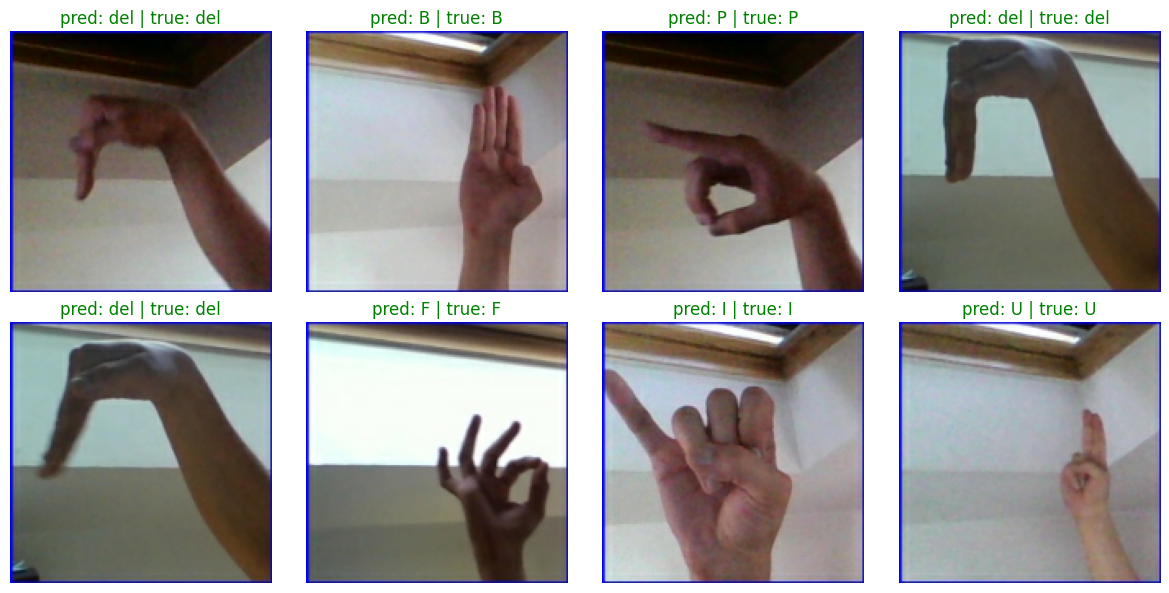

In [15]:
loaded = keras.models.load_model(os.path.join(OUT_DIR, "asl_model.keras"))
imgs, lbls = next(iter(test_ds))
p_orig = model.predict(imgs, verbose=0)
p_load = loaded.predict(imgs, verbose=0)
print("Max difference (original vs loaded):", float(np.abs(p_orig - p_load).max()))

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(imgs[i].numpy().astype("uint8"))
    pred = class_names[int(np.argmax(p_load[i]))]
    true = class_names[int(np.argmax(lbls[i].numpy()))]
    plt.title(f"pred: {pred} | true: {true}", color="green" if pred == true else "red")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 13. (Optional) TensorFlow.js format - web ke liye
Agar ye cell fail ho to koi masla nahi: `.keras`, `saved_model` aur `.tflite` pehle se save hain. Ye cell training ke baad hi chalana (install se Colab ke packages badal sakte hain).

In [16]:
!pip install -q tensorflowjs
!tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model {OUT_DIR}/saved_model {OUT_DIR}/web_model
!ls {OUT_DIR}/web_model

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langsmith 0.14.11 requires packaging>=23.2, but you have packaging 20.9 which is incompatible.
langchain-core 1.6.12 requires packaging>=23.2.0, but you have packaging 20.9 which is incompatible.
shap 0.54.1 requires packaging>20.9, but you have packaging 20.9 which is incompatible.
google-cloud-bigquery 3.46.2 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
sphinx 8.2.3 requires packaging>=23.0, but you have packaging 20.9 which is incompatible.
scikit-image 0.25.2 requires packaging>=21, but you have packaging 20.9 which is incompatible.
google-adk 2.7.1 requires packaging>=21, but you have packaging 20.9 which is incompatible.
libpysal 4.14.1 requi

## 14. Download karo (zip) ya Google Drive mein save karo

In [17]:
shutil.make_archive("/content/asl_output", "zip", OUT_DIR)
print("Zip ready: /content/asl_output.zip")

from google.colab import files
files.download("/content/asl_output.zip")

Zip ready: /content/asl_output.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Optional: Google Drive mein copy (agar chahiye to is cell ko run karo)
from google.colab import drive
drive.mount("/content/drive")
shutil.copytree(OUT_DIR, "/content/drive/MyDrive/asl_output", dirs_exist_ok=True)
print("Drive mein save ho gaya: MyDrive/asl_output")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mein save ho gaya: MyDrive/asl_output


In [19]:
def load_image(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE, color_mode="rgb")
    return keras.utils.img_to_array(img)   # pixels 0-255, rescale model ke andar hai

def predict_image(path, top_k=3):
    arr = load_image(path)
    probs = model.predict(arr[None], verbose=0)[0]
    idx = np.argsort(probs)[::-1][:top_k]
    return arr, [(class_names[i], float(probs[i])) for i in idx]

def show_predictions(paths, true_labels=None, cols=4):
    rows = (len(paths) + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4.2 * rows))
    for n, p in enumerate(paths):
        arr, top = predict_image(p)
        plt.subplot(rows, cols, n + 1)
        plt.imshow(arr.astype("uint8"))
        pred, conf = top[0]
        title = f"{pred}  ({conf:.0%})"
        color = "black"
        if true_labels is not None and true_labels[n] is not None:
            color = "green" if pred == true_labels[n] else "red"
            title += f"\ntrue: {true_labels[n]}"
        title += "\n2nd: %s (%.0f%%)" % (top[1][0], top[1][1] * 100)
        plt.title(title, color=color, fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Saving AA_test.jpg to AA_test.jpg


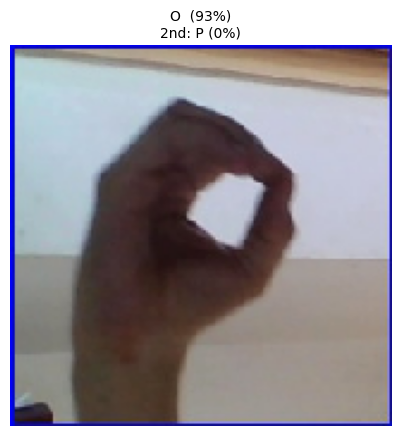

AA_test.jpg -> O 93.1%, P 0.3%, S 0.3%


In [23]:
from google.colab import files
uploaded = files.upload()

paths = [os.path.join("/content", n) for n in uploaded.keys()]
labels = []
for p in paths:
    stem = os.path.splitext(os.path.basename(p))[0]
    guess = stem.split("_")[0].split(" ")[0].split("(")[0]
    labels.append(next((c for c in class_names if c.lower() == guess.lower()), None))

show_predictions(paths, true_labels=labels)

for p in paths:
    _, top = predict_image(p, top_k=3)
    print(os.path.basename(p), "->", ", ".join(f"{n} {c:.1%}" for n, c in top))

Saving T_test.jpg to T_test.jpg


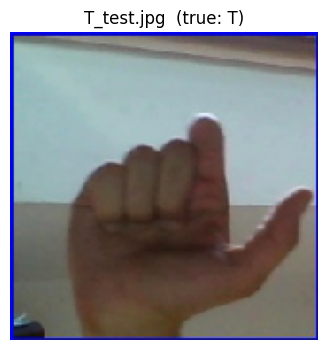

model    | jawab    | confidence | top-3
phase1   | T        |      69.8% | T 70%, S 8%, E 3%  OK
phase2   | T        |      93.9% | T 94%, space 0%, nothing 0%  OK
final    | T        |      93.9% | T 94%, space 0%, nothing 0%  OK
memory   | T        |      93.9% | T 94%, space 0%, nothing 0%  OK
----------------------------------------------------------------------

SCORE (sirf wo images jin ka naam letter se shuru hua):
  phase1  : 1/1
  phase2  : 1/1
  final   : 1/1
  memory  : 1/1


In [24]:
from google.colab import files

# --- 3 saved models + memory wala model load karo ---
model_files = {
    "phase1": "best_phase1.keras",
    "phase2": "best_phase2.keras",
    "final":  "asl_model.keras",
}
all_models = {}
for name, fname in model_files.items():
    f = os.path.join(OUT_DIR, fname)
    if os.path.exists(f):
        all_models[name] = keras.models.load_model(f, compile=False)
    else:
        print("File nahi mili, skip:", fname)
all_models["memory"] = model      # jo abhi Colab ki memory mein hai (Cell B yehi use karta hai)

# --- Images upload ---
uploaded = files.upload()
img_paths = [os.path.join("/content", n) for n in uploaded.keys()]

# --- Har image par har model ka jawab ---
summary = {name: [0, 0] for name in all_models}   # [sahi, total]

for p in img_paths:
    arr = load_image(p)
    stem = os.path.splitext(os.path.basename(p))[0]
    guess = stem.split("_")[0].split(" ")[0].split("(")[0]
    true = next((c for c in class_names if c.lower() == guess.lower()), None)

    plt.figure(figsize=(4, 4))
    plt.imshow(arr.astype("uint8"))
    plt.title(os.path.basename(p) + (f"  (true: {true})" if true else ""))
    plt.axis("off")
    plt.show()

    print(f"{'model':8s} | {'jawab':8s} | {'confidence':10s} | top-3")
    for name, m in all_models.items():
        probs = m.predict(arr[None], verbose=0)[0]
        idx = np.argsort(probs)[::-1][:3]
        top3 = ", ".join(f"{class_names[i]} {probs[i]:.0%}" for i in idx)
        pred = class_names[idx[0]]
        mark = ""
        if true:
            summary[name][1] += 1
            if pred == true:
                summary[name][0] += 1
                mark = "  OK"
            else:
                mark = "  GALAT"
        print(f"{name:8s} | {pred:8s} | {probs[idx[0]]:10.1%} | {top3}{mark}")
    print("-" * 70)

# --- Aakhir mein score ---
if any(t for _, t in summary.values()):
    print("\nSCORE (sirf wo images jin ka naam letter se shuru hua):")
    for name, (ok, tot) in summary.items():
        print(f"  {name:8s}: {ok}/{tot}")